# Big Data Analytics - Topic Drift Assignment

Thomas Timmermans - 2365790

Milan Muroni - 2262576

**Gekozen Dataset:** [Data Mining / Database Systems]



In [2]:
%pip install bertopic

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 0. Imports & Setup

In [3]:
import numpy as np
import pandas as pd
import ast
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans
from bertopic import BERTopic


c:\Users\milan\AppData\Local\Programs\Python\Python313\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


---  
## 1. Data Inladen & Preprocessing
Specificeer de gekozen dataset (Data Mining of Database Systems) en bereid de titels voor.

In [13]:
# Data inladen uit het tekstbestand
dataset_file = "data_mining_publications.txt"
publications = []

with open(dataset_file, "r", encoding="utf-8") as f:
    for line in f:
        line = line.strip()
        if line:
            # Converteer string dict naar een Python dictionary
            publications.append(ast.literal_eval(line))

df = pd.DataFrame(publications)
# Converteer jaar naar integer
df['year'] = df['year'].astype(int)

print(f"Totaal aantal publicaties geladen: {len(df)}")
df.head()

Totaal aantal publicaties geladen: 16538


,publication_type,booktitle,journal,year,title
0,inproceedings,SDM,,2019,Feature selection as Monte-Carlo Search in Gro...
1,inproceedings,SDM,,2002,Mining Relationship between Triggering and Con...
2,inproceedings,SDM,,2007,Segmentations with Rearrangements.
3,inproceedings,SDM,,2021,MT-STNets: Multi-Task Spatial-Temporal Network...
4,inproceedings,SDM,,2006,A Semantic Approach for Mining Hidden Links fr...


---  
## 2. Part 1: Topic Modeling

### 2.1 Conventionele Benadering (TF-IDF + Clustering)

#### A TF-IDF met ondersteuning voor n-grams (bijv. "big data")

In [14]:

tfidf_vectorizer = TfidfVectorizer(
    stop_words="english", # verwijder Engelse stopwoorden
    ngram_range=(1, 3), # kijk ook naar combinaties van 2 en 3 woorden
    
)
tfidf_matrix = tfidf_vectorizer.fit_transform(df['title'])

#### B Clustering met K-Means

In [15]:
num_clusters = 10  # verdeel publications in xxx verschillende topics/clusters
kmeans = KMeans(n_clusters=num_clusters, random_state=42)
df['cluster_tfidf'] = kmeans.fit_predict(tfidf_matrix)

#### C Topicbeschrijving per cluster afleiden

In [16]:
feature_names = np.array(tfidf_vectorizer.get_feature_names_out()) #haalt lijst op van unieke woorden en n-grams die TF-IDF heeft gebruikt
order_centroids = kmeans.cluster_centers_.argsort()[:, ::-1] #rangschikt de TF-IDF scores van hoog naar laag

print("=== Topics ===")
for i in range(num_clusters):
    top_words = feature_names[order_centroids[i, :7]]
    print(f"Cluster {i}: {', '.join(top_words)}")

=== Topics ===
Cluster 0: semi supervised, supervised, semi, supervised learning, semi supervised learning, learning, semi supervised multi
Cluster 1: network, prediction, temporal, neural network, graph, neural, spatio
Cluster 2: data, mining, data mining, data streams, streams, learning, analysis
Cluster 3: detection, classification, anomaly, anomaly detection, based, outlier, outlier detection
Cluster 4: time series, series, time, multivariate time, multivariate time series, multivariate, time series classification
Cluster 5: learning, mining, based, graph, model, using, recommendation
Cluster 6: clustering, based, data, based clustering, spectral, spectral clustering, subspace clustering
Cluster 7: models, discovery, knowledge discovery, knowledge, language models, language, topic
Cluster 8: networks, neural networks, neural, social networks, graph neural networks, graph neural, social
Cluster 9: multi, learning, reinforcement, reinforcement learning, task, label, multi task


### 2.2 Text Embedding Benadering (BERTopic)

In [8]:
topic_model = BERTopic(language="english", calculate_probabilities=False, verbose=True)
topics, _ = topic_model.fit_transform(df['title'])

df["bertopic_cluster"] = topics

2026-11-04 13:23:28,952 - BERTopic - Embedding - Transforming documents to embeddings.
Batches: 100%|██████████| 517/517 [00:39<00:00, 12.97it/s]
2026-11-04 13:24:10,010 - BERTopic - Embedding - Completed ✓
2026-11-04 13:24:10,012 - BERTopic - Dimensionality - Fitting the dimensionality reduction algorithm
2026-11-04 13:25:46,161 - BERTopic - Dimensionality - Completed ✓
2026-11-04 13:25:46,163 - BERTopic - Cluster - Start clustering the reduced embeddings
2026-11-04 13:25:50,501 - BERTopic - Cluster - Completed ✓
2026-11-04 13:25:50,514 - BERTopic - Representation - Fine-tuning topics using representation models.
2026-11-04 13:25:50,859 - BERTopic - Representation - Completed ✓


In [9]:
print("\n=== BERTopic topics===")
topic_info = topic_model.get_topic_info() # hij maakt misschien 50 "clusters" = topics
print(topic_info) # toon de belangrijkste gevonden topics


=== BERTopic topics===
     Topic  Count                                               Name  \
0       -1   5074                        -1_mining_of_clustering_and   
1        0    654  0_recommendation_recommender_collaborative_fil...   
2        1    237                1_health_electronic_records_patient   
3        2    209  2_privacy_private_privacypreserving_differenti...   
4        3    179        3_reinforcement_policy_multiagent_imitation   
..     ...    ...                                                ...   
272    271     10      271_hypergraphs_realworld_directed_generators   
273    272     10        272_demand_passenger_multigraph_situational   
274    273     10    273_latent_variable_factor_multilayerstructured   
275    274     10       274_logistic_regression_glmnet_l1regularized   
276    275     10   275_personalization_profiling_user_virtualkernel   

                                        Representation  \
0    [mining, of, clustering, and, graphs, the, dat..

---  
## 3. Part 2: Topic Evolution (Topic Drift Visualisatie)
Visualiseer hoe het aantal publicaties per onderwerp evolueert door de jaren heen.

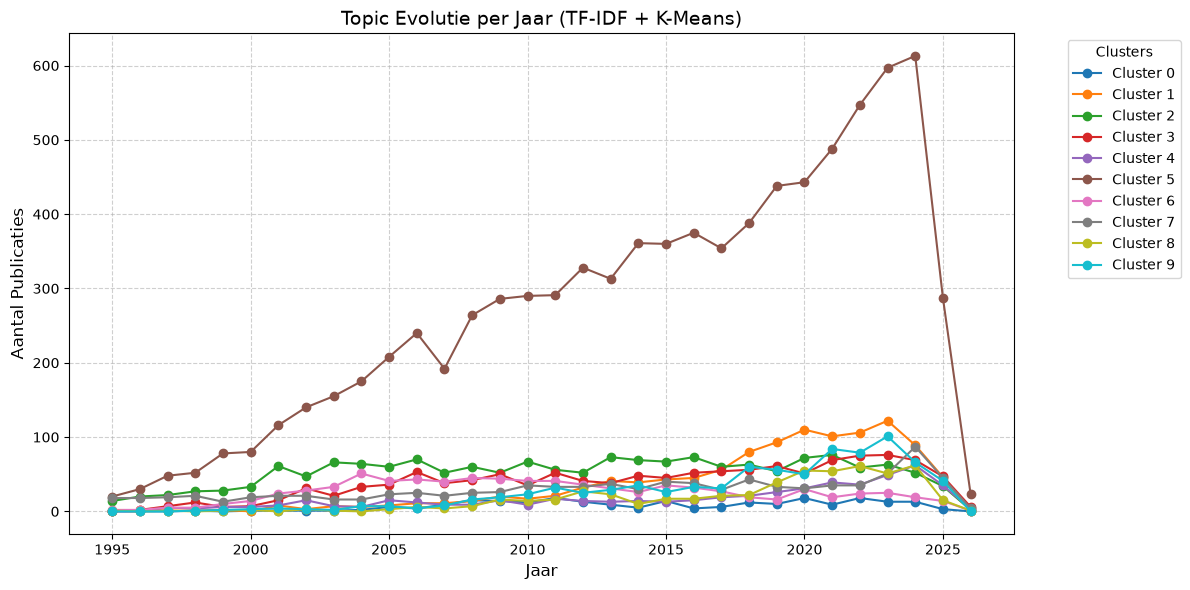

In [19]:
import matplotlib.pyplot as plt

# 1. Groepeer de data per jaar en per cluster, en tel het aantal artikelen
df_evolution_kmeans = df.groupby(['year', 'cluster_tfidf']).size().unstack(fill_value=0)

# 2. Geef de kolommen nette namen
df_evolution_kmeans.columns = [f"Cluster {i}" for i in df_evolution_kmeans.columns]

# 3. Visualisatie met Matplotlib
plt.figure(figsize=(12, 6))
for column in df_evolution_kmeans.columns:
    plt.plot(df_evolution_kmeans.index, df_evolution_kmeans[column], marker='o', label=column)

plt.title("Topic Evolutie per Jaar (TF-IDF + K-Means)", fontsize=14)
plt.xlabel("Jaar", fontsize=12)
plt.ylabel("Aantal Publicaties", fontsize=12)
plt.grid(True, linestyle="--", alpha=0.6)
plt.legend(title="Clusters", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

In [ ]:
# Bereken de topic evolutie over de jaren heen middels BERTopic
topics_over_time = topic_model.topics_over_time(df['title'], df['year'])

# Visualiseer de meest relevante top-5 onderwerpen (zonder ruis/cluster -1)
fig = topic_model.visualize_topics_over_time(topics_over_time, top_n_topics=5)
fig.show()

0it [00:00, ?it/s]

19it [00:02,  6.56it/s]

---  
## 4. (Optioneel) Extra Challenge: Temporele Clustering
Neem het publicatiejaar mee in de clustering om compacte tijdclusters te bevoordelen.

---  
## 5. Uitvoeringstijd & Geheugengebruik (Voor Rapport)
Gebruik deze cel om runtime en memory op te meten ten behoeve van Sectie 4.2 in het rapport.